# 03 - The logistic equation: equilibria, phase line, exact solution, harvesting

**MATH 331 - Differential Equations.** Syllabus unit U4 (logistic equation, autonomous
equations and the phase line), with links to U2 (separable equations, existence and
uniqueness) and U14 (numerical methods). Lecture plan: Session 7 (and Sessions 8 and 29).

**References**
* J. Lebl, *Notes on Diffy Qs* (`ode/FullText_Diff_Eq_For_Engineers.pdf`): **Section 1.6,
  Autonomous equations**, whose notation $x' = kx(M-x)$ and examples (Figures 1.6.2 and
  1.6.5-1.6.7) we follow; Section 1.3 (separable equations)
  Section 1.5 (Bernoulli equations).
* W.A. Adkins and M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012), Section 1.1,
  exercise "the logistic growth law" (birth rate $\propto P$, death rate $\propto P^2$).
* J.D. Logan, *An Introduction to Nonlinear Differential Equations* (Wiley, 2007), Chapter 1
  (logistic law, harvesting, bifurcations).

**What you will learn**
1. Why the logistic law is a natural correction of exponential growth.
2. How to get the long-term behaviour **without solving**: critical points, phase line, stability.
3. The exact solution, with every case: $0 < x_0 < M$, $x_0 > M$, $x_0 = 0$ and $x_0 < 0$
   (finite-time blow-up).
4. Why Euler's method can produce oscillations that the true solution never has.
5. What happens when the population is harvested: a **bifurcation**.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (analytic solutions, Euler/Heun/RK4, slope fields, phase lines).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 1. The model

Exponential growth (notebook 01) assumes a constant per-capita growth rate. With limited
resources, the per-capita rate should **decrease as the population grows** and vanish at a
limiting population $M$. The simplest choice is a linear decrease, $\frac{1}{x}\frac{dx}{dt} = k(M - x)$:

$$
\boxed{\;\frac{dx}{dt} = k\,x\,(M - x), \qquad x(0) = x_0, \qquad k > 0,\; M > 0\;}
$$

(Lebl, Section 1.6). $M$ is the **carrying capacity**, the maximum sustainable population.
An equivalent form, common in biology, is $x' = r\,x\,(1 - x/K)$ with $r = kM$ (the growth rate
of a small population) and $K = M$.

*Another derivation* (Adkins and Davidson, Exercise 1.1.2): births proportional to $x$
($b\,x$), deaths proportional to $x^2$ (crowding: encounters between pairs, $d\,x^2$), so
$x' = bx - dx^2 = d\,x\,(b/d - x)$, which is logistic with $k = d$, $M = b/d$.

**Classification.** First order, **nonlinear** (the $x^2$ term), autonomous, separable. It is
also a Bernoulli equation (Lebl, Section 1.5): the substitution $v = 1/x$ makes it linear.

**Existence and uniqueness.** $f(x) = kx(M-x)$ is a polynomial, so $f$ and $f'$ are continuous
everywhere. By Picard's theorem (Lebl, Theorem 1.2.1) every IVP has a unique solution near $t_0$.
As we will see, however, the solution **need not exist for all times**.

## 2. Long-term behaviour without solving: critical points and the phase line

For an autonomous equation $x' = f(x)$, the zeros of $f$ are **critical points**, and each one
gives a constant **equilibrium solution** (Lebl, Section 1.6):

$$
f(x) = kx(M - x) = 0 \iff x = 0 \ \text{or}\ x = M.
$$

Between consecutive critical points $f$ has a constant sign (it is continuous), so every
solution moves monotonically **up** where $f > 0$ and **down** where $f < 0$. It can never cross
an equilibrium, by uniqueness. This information fits in the **phase line** (*phase diagram*).

**Stability test (linearization).** Near an equilibrium $x^*$, write $x = x^* + \varepsilon$:
$\varepsilon' = f(x^*+\varepsilon) \approx f'(x^*)\,\varepsilon$, so small perturbations behave like
$e^{f'(x^*)t}$:

* $f'(x^*) < 0$: perturbations die out, **stable** (attracting);
* $f'(x^*) > 0$: perturbations grow, **unstable**;
* $f'(x^*) = 0$: the test is **inconclusive** (look at the signs of $f$ on both sides).

Here $f'(x) = kM - 2kx$, so $f'(0) = kM > 0$ (unstable) and $f'(M) = -kM < 0$ (stable).
That is Lebl's conclusion, read off the slope field of Figure 1.6.2.

critical point x* = 0:  f'(x*) = M*k  ->  unstable
critical point x* = M:  f'(x*) = -M*k  ->  stable


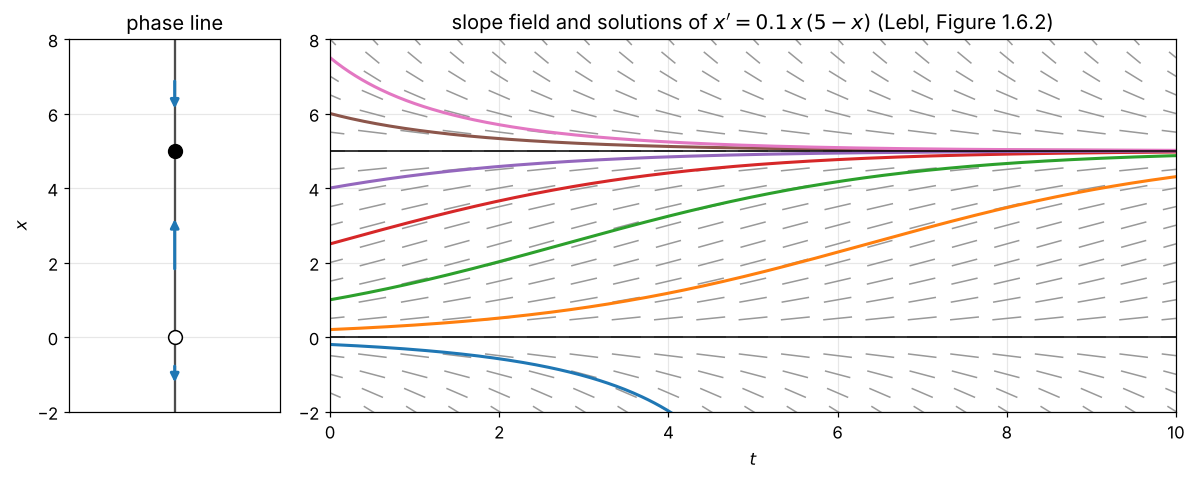

In [2]:
x = sp.symbols("x", real=True)
k_s, M_s = sp.symbols("k M", positive=True)
f = k_s * x * (M_s - x)
for xs in sp.solve(sp.Eq(f, 0), x):
    slope = sp.simplify(f.diff(x).subs(x, xs))
    print(f"critical point x* = {xs}:  f'(x*) = {slope}  ->  "
          f"{ol.classify_equilibrium(float(slope.subs({k_s: 0.1, M_s: 5})))}")

k0, M0 = 0.1, 5.0                                            # Lebl, Figure 1.6.2
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1, 4]})
ol.phase_line(ax1, lambda xx: k0 * xx * (M0 - xx), [0.0, M0], (-2, 8))
ax1.set_ylabel("$x$")
ax1.set_title("phase line")
ol.slope_field(ax2, lambda tt, xx: k0 * xx * (M0 - xx), (0, 10), (-2, 8), n=21)
t = np.linspace(0, 10, 400)
for x0 in (-0.2, 0.2, 1, 2.5, 4, 6, 7.5):
    ax2.plot(t, ol.logistic_solution(t, x0, k0, M0), lw=2)
ax2.axhline(M0, color="k", lw=1)
ax2.axhline(0, color="k", lw=1)
ax2.set_xlabel("$t$")
ax2.set_title(r"slope field and solutions of $x' = 0.1\,x\,(5 - x)$ (Lebl, Figure 1.6.2)")
plt.tight_layout()
plt.show()

The phase line (filled dot = stable, open dot = unstable) predicts, **without solving**
(Lebl, Section 1.6):

$$
\lim_{t\to\infty} x(t) = \begin{cases} M & \text{if } x_0 > 0,\\ 0 & \text{if } x_0 = 0,\\
\text{does not exist } (\to -\infty) & \text{if } x_0 < 0. \end{cases}
$$

The slope field cannot tell **how fast** a solution with $x_0 < 0$ goes to $-\infty$. The exact
solution shows that it does so in **finite time**.

## 3. The exact solution

Assume $x_0 \neq 0, M$ (otherwise the solution is constant). By uniqueness, $x(t)$ never reaches
$0$ or $M$, so we may divide by $x(M-x)$ and use partial fractions:

$$
\frac{1}{x(M-x)} = \frac{1}{M}\left(\frac{1}{x} + \frac{1}{M-x}\right)
\;\Longrightarrow\;
\frac{1}{M}\int_{x_0}^{x}\left(\frac{1}{s} + \frac{1}{M-s}\right)ds = \int_0^t k\,d\tau
\;\Longrightarrow\;
\ln\left|\frac{x\,(M - x_0)}{x_0\,(M - x)}\right| = kMt .
$$

Since $x/(M-x)$ keeps the sign of $x_0/(M-x_0)$, the absolute value can be dropped, and solving for $x$:

$$
\boxed{\;x(t) = \frac{M\,x_0}{x_0 + (M - x_0)\,e^{-kMt}}\;}
$$

The formula also covers $x_0 = 0$ and $x_0 = M$. Reading it case by case:

* **$0 < x_0 < M$**: the denominator decreases from $M$ to $x_0$, so $x(t)$ increases to $M$.
* **$x_0 > M$**: the denominator increases from $M$ to $x_0$, so $x(t)$ decreases to $M$.
* **$x_0 < 0$**: the denominator decreases from $M>0$ to $x_0<0$, so it **vanishes** at
  $$t^* = \frac{1}{kM}\ln\frac{M - x_0}{-x_0} \quad (> 0),$$
  where $x(t)\to-\infty$. The solution exists only on $[0, t^*)$, even though $f$ is a smooth
  polynomial. This is the same phenomenon as $y' = y^2$ in Lebl, Example 1.2.3.

**Inflection point.** Differentiating the equation, $x'' = f'(x)\,x' = k(M - 2x)\,kx(M-x)$. For
$0 < x_0 < M/2$ the curve changes concavity when it crosses $x = M/2$, at
$t_{i} = \frac{1}{kM}\ln\frac{M - x_0}{x_0}$. There the growth is **fastest**, with $x'_{max} = kM^2/4$.

In [3]:
t = sp.symbols("t", real=True)
x0_s = sp.symbols("x_0", real=True)
X = sp.Function("x")
logistic_ode = sp.Eq(X(t).diff(t), k_s * X(t) * (M_s - X(t)))
closed_form = M_s * x0_s / (x0_s + (M_s - x0_s) * sp.exp(-k_s * M_s * t))
display(Math(r"x(t) = " + sp.latex(closed_form)))
# substitute the closed form into the equation: the residual must simplify to zero
residual = sp.simplify(closed_form.diff(t) - k_s * closed_form * (M_s - closed_form))
print("residual of the ODE:", residual, "| initial value:", sp.simplify(closed_form.subs(t, 0)))
print("SymPy checkodesol:", sp.checkodesol(logistic_ode, sp.Eq(X(t), closed_form)))

t_inflection = sp.solve(sp.Eq(closed_form, M_s / 2), t)[0]
display(Math(r"t_i = " + sp.latex(sp.simplify(t_inflection))))

<IPython.core.display.Math object>

residual of the ODE: 0 | initial value: x_0
SymPy checkodesol: (True, 0)


<IPython.core.display.Math object>

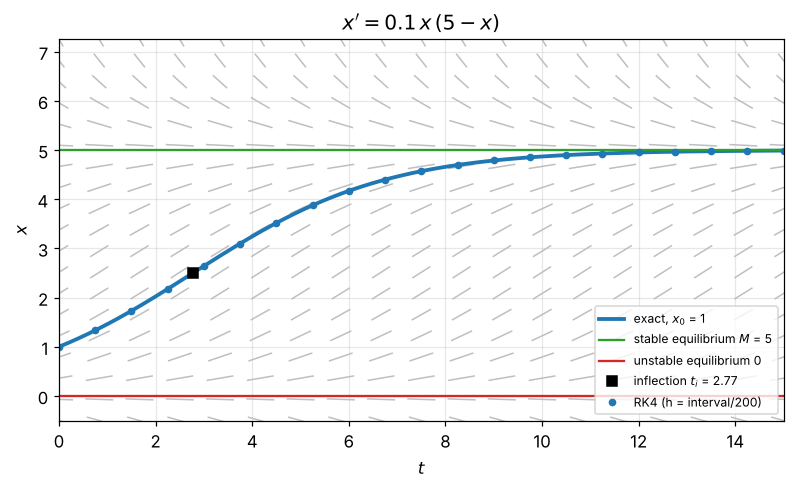

In [4]:
def plot_logistic(k=0.1, M=5.0, x0=1.0, t_end=15.0):
    """Exact solution with equilibria, inflection point or blow-up time, and RK4 check."""
    t = np.linspace(0, t_end, 600)
    x = ol.logistic_solution(t, x0, k, M)
    fig, ax = plt.subplots(figsize=(8.5, 4.5))
    top = max(M, x0) * 1.35 + 0.5
    bottom = min(0.0, x0) * 1.5 - 0.5
    ol.slope_field(ax, lambda tt, xx: k * xx * (M - xx), (0, t_end), (bottom, top), n=19, color="0.75")
    ax.plot(t, x, lw=2.5, label=f"exact, $x_0$ = {x0:g}")
    ax.axhline(M, color="C2", lw=1.5, label=f"stable equilibrium $M$ = {M:g}")
    ax.axhline(0, color="C3", lw=1.5, label="unstable equilibrium 0")
    info = ""
    if 0 < x0 < M / 2:
        t_i = np.log((M - x0) / x0) / (k * M)
        if t_i <= t_end:
            ax.plot([t_i], [M / 2], "ks", label=rf"inflection $t_i$ = {t_i:.3g}")
    if x0 < 0:
        t_star = ol.logistic_blowup_time(x0, k, M)
        ax.axvline(t_star, color="C3", ls="--", label=rf"blow-up $t^*$ = {t_star:.3g}")
        info = "  (solution exists only for t < t*)"
        t_rk_end = min(t_end, 0.98 * t_star)
    else:
        t_rk_end = t_end
    # independent numerical check with RK4 (step chosen to divide the interval exactly)
    n = 200
    t_rk, x_rk = ol.rk4(lambda tt, xx: k * xx * (M - xx), (0, t_rk_end), x0, t_rk_end / n)
    ax.plot(t_rk[::10], x_rk[::10], "o", color="C0", ms=4, label="RK4 (h = interval/200)")
    ax.set_ylim(bottom, top)
    ax.set_xlabel("$t$")
    ax.set_ylabel("$x$")
    ax.set_title(rf"$x' = {k:g}\,x\,({M:g} - x)$" + info)
    ax.legend(loc="lower right", fontsize=8)
    plt.show()


plot_logistic()

**Explore** (running kernel). Try $x_0$ just above 0, between $M/2$ and $M$, above $M$, and
negative (blow-up). Notice that $k$ only sets the **time scale** ($kM$ has units of
$1/\text{time}$), while $M$ sets the level.

In [5]:
interact(plot_logistic,
         k=FloatSlider(value=0.1, min=0.01, max=0.5, step=0.01, description="k", continuous_update=False),
         M=FloatSlider(value=5, min=1, max=10, step=0.5, description="M", continuous_update=False),
         x0=FloatSlider(value=1, min=-1, max=12, step=0.1, description="x0", continuous_update=False),
         t_end=FloatSlider(value=15, min=2, max=50, step=1, description="t max", continuous_update=False));

interactive(children=(FloatSlider(value=0.1, continuous_update=False, description='k', max=0.5, min=0.01, step…

## 4. A warning about Euler's method: oscillations that are not there

Euler's method (Lebl, Section 1.7) applied to the logistic equation reads
$x_{n+1} = x_n + h\,k\,x_n(M - x_n)$. Write $x_n = M + e_n$ near the stable equilibrium and drop
the $e_n^2$ term:

$$
e_{n+1} \approx (1 - hkM)\,e_n .
$$

* $0 < hkM < 1$: the error decreases monotonically, as for the true solution;
* $1 < hkM < 2$: the factor is negative, so the iterates **overshoot $M$ and oscillate** while
  converging. The exact solution never crosses $M$: these oscillations are an artefact;
* $hkM > 2$: the equilibrium becomes **unstable for the numerical scheme** (period doubling and,
  for larger $h$, chaotic behaviour: the *logistic map*).

The stability of the numerical method depends on the step size: the first glimpse of
**numerical stability** (Lebl, end of Section 1.7; notebook 04).

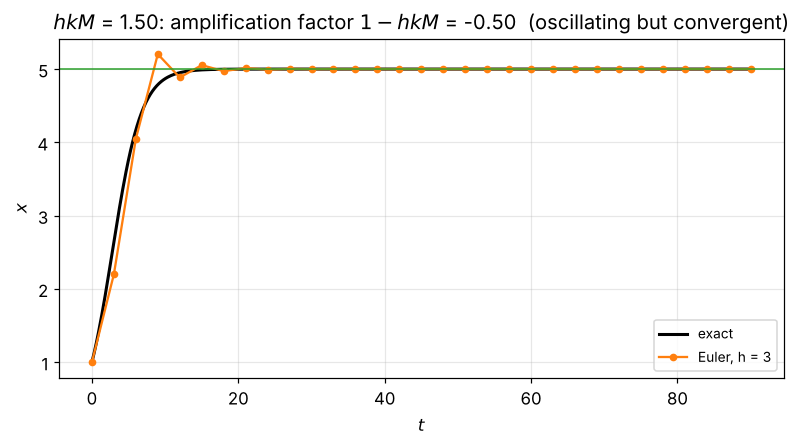

In [6]:
def plot_euler_logistic(hkM=1.5, k=0.1, M=5.0, x0=1.0, n_steps=30):
    """Euler iterates of the logistic equation for a given value of h k M."""
    h = hkM / (k * M)
    t_e, x_e = ol.euler(lambda tt, xx: k * xx * (M - xx), (0, n_steps * h), x0, h)
    t = np.linspace(0, n_steps * h, 600)
    fig, ax = plt.subplots(figsize=(8.5, 4))
    ax.plot(t, ol.logistic_solution(t, x0, k, M), "k", lw=2, label="exact")
    ax.plot(t_e, x_e, "o-", color="C1", ms=4, label=f"Euler, h = {h:.3g}")
    ax.axhline(M, color="C2", lw=1)
    regime = ("monotone" if hkM < 1 else "oscillating but convergent" if hkM < 2
              else "numerically UNSTABLE equilibrium")
    ax.set_title(rf"$hkM$ = {hkM:.2f}: amplification factor $1 - hkM$ = {1 - hkM:.2f}  ({regime})")
    ax.set_xlabel("$t$")
    ax.set_ylabel("$x$")
    ax.legend()
    plt.show()


plot_euler_logistic()

In [7]:
interact(plot_euler_logistic,
         hkM=FloatSlider(value=1.5, min=0.1, max=2.9, step=0.05, description="h k M",
                         continuous_update=False),
         k=FloatSlider(value=0.1, min=0.05, max=0.5, step=0.05, description="k", continuous_update=False),
         M=FloatSlider(value=5, min=1, max=10, step=0.5, description="M", continuous_update=False),
         x0=FloatSlider(value=1, min=0.1, max=9, step=0.1, description="x0", continuous_update=False),
         n_steps=IntSlider(value=30, min=5, max=100, description="steps", continuous_update=False));

interactive(children=(FloatSlider(value=1.5, continuous_update=False, description='h k M', max=2.9, min=0.1, s…

## 5. Logistic growth with harvesting: a bifurcation

Removing individuals at a **constant rate** $h \ge 0$ (fishing, hunting; Lebl's tongue-in-cheek
"alien" example, Section 1.6):

$$
\frac{dx}{dt} = k\,x\,(M - x) - h .
$$

The critical points solve $kx^2 - kMx + h = 0$:

$$
A, B = \frac{kM \pm \sqrt{(kM)^2 - 4hk}}{2k}.
$$

Three regimes, separated by the **critical harvesting rate** $h_c = kM^2/4$ (the maximum of
$kx(M-x)$, reached at $x = M/2$):

| harvesting | critical points | behaviour |
|---|---|---|
| $h < h_c$ | $B < A$, both real | $A$ stable, $B$ unstable: the population survives if it starts above $B$ |
| $h = h_c$ | $A = B = M/2$ | one equilibrium, attracting from above and repelling from below |
| $h > h_c$ | none | the population always collapses, whatever $x_0$ |

Lebl's numbers, with $M = 8$ and $k = 0.1$: $h = 1$ gives $B \approx 1.55$ and $A \approx 6.45$;
$h = 1.6 = h_c$ gives $A = B = 4$; $h = 2$ gives no equilibria (Figures 1.6.5-1.6.7).

**About the word "unstable" at $h = h_c$.** Lebl calls the double point unstable. That is
correct: an equilibrium is stable only if *all* nearby solutions stay nearby, and here those
starting just below it run away. Many texts call such a point **semi-stable**, because it
still attracts from one side. With $f'(x^*) = 0$ the linearization test is inconclusive, and
the sign of $f$ on each side decides (the half-grey dot on the phase line below).

At $h = h_c$ two equilibria collide and disappear: a **saddle-node bifurcation**. Near it the
equilibrium state is fragile. A small extra harvest, or a small drop in the population, and
it collapses.

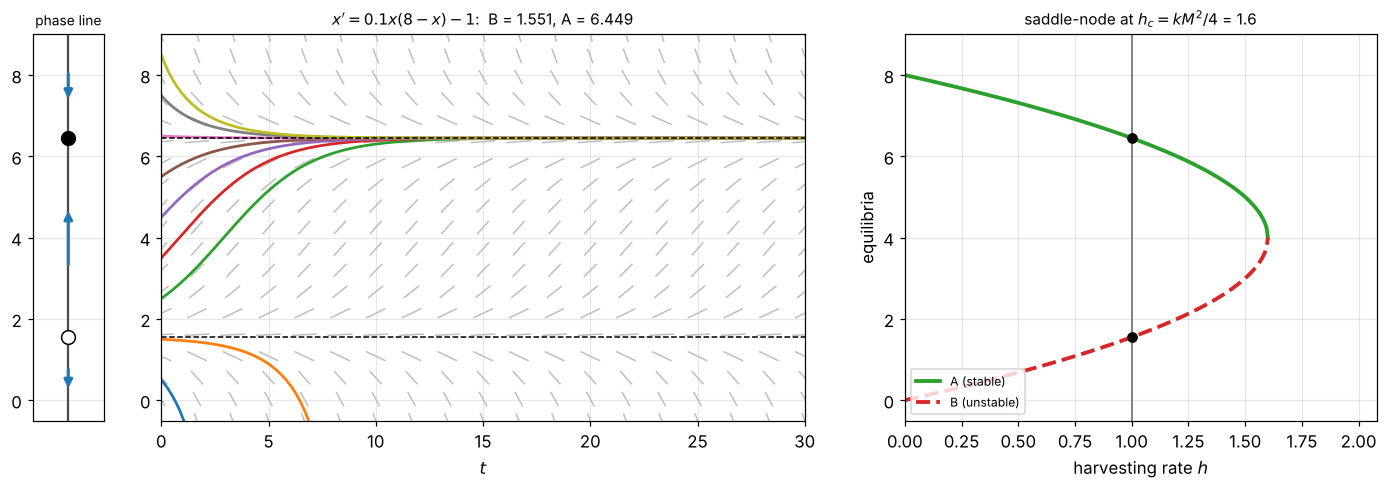

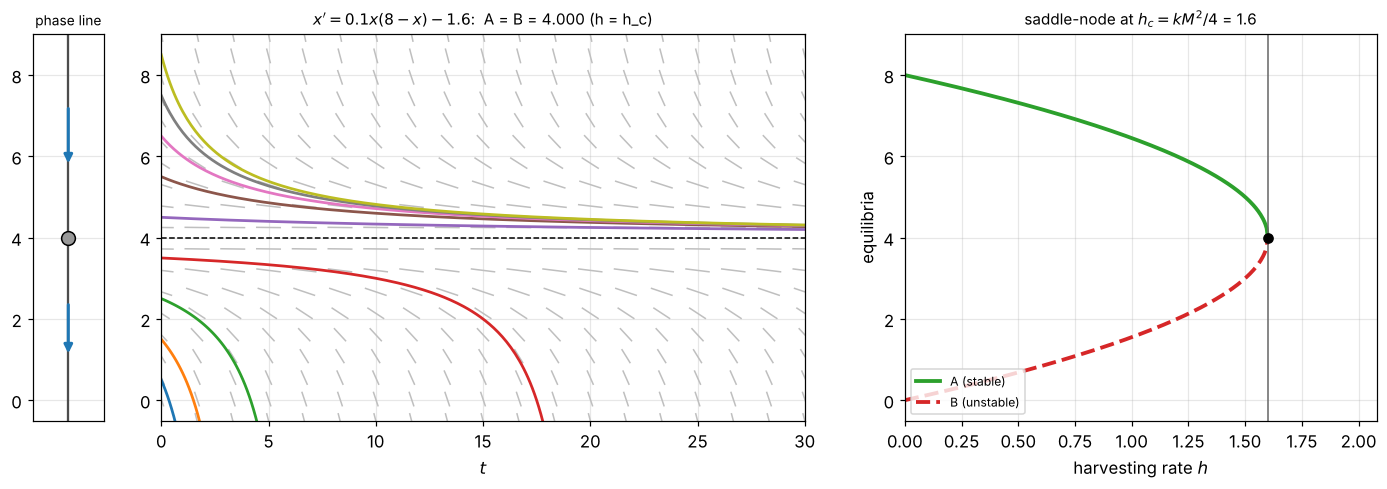

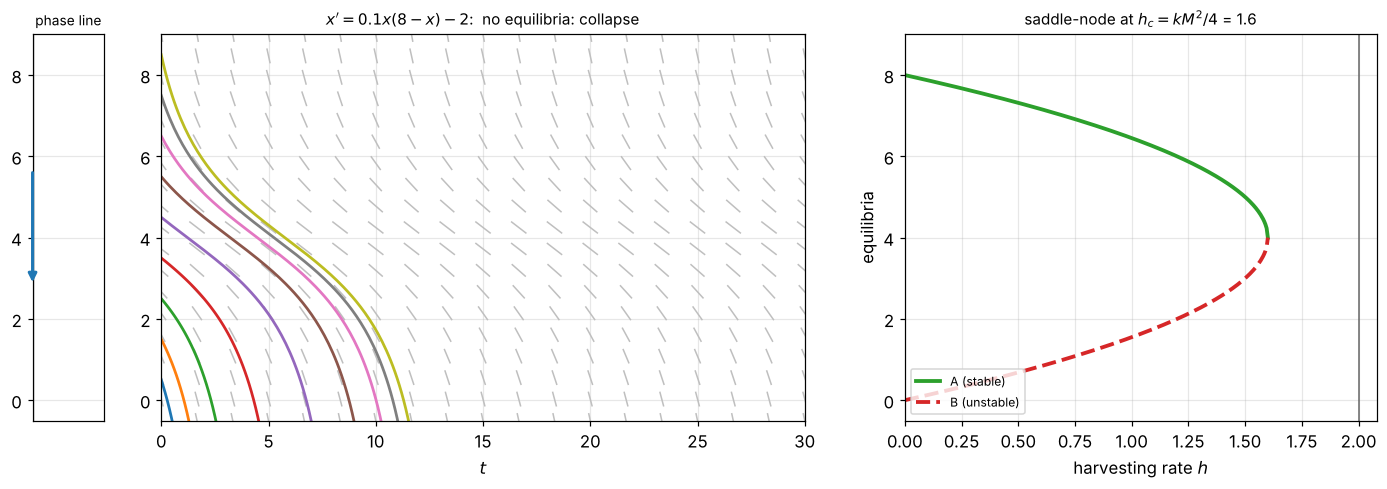

In [8]:
def plot_harvest(h=1.0, k=0.1, M=8.0, t_end=30.0):
    """Phase line, slope field with solutions, and bifurcation diagram of harvested logistic growth."""
    f = lambda xx: k * xx * (M - xx) - h                                    # noqa: E731
    eq = ol.harvesting_equilibria(k, M, h)
    fig = plt.figure(figsize=(13, 4.5))
    ax_pl = fig.add_axes([0.04, 0.12, 0.05, 0.78])
    ax_sf = fig.add_axes([0.13, 0.12, 0.45, 0.78])
    ax_bd = fig.add_axes([0.65, 0.12, 0.33, 0.78])
    ol.phase_line(ax_pl, f, list(eq), (-0.5, M + 1))
    ax_pl.set_title("phase line", fontsize=9)
    ol.slope_field(ax_sf, lambda tt, xx: f(xx), (0, t_end), (-0.5, M + 1), n=19, color="0.75")
    for x0 in np.linspace(0.5, M + 0.5, 9):
        sol = solve_ivp(lambda tt, xx: f(xx), (0, t_end), [x0], max_step=0.1,
                        events=lambda tt, xx: xx[0] + 0.5)   # stop when the population is gone
        ax_sf.plot(sol.t, sol.y[0], lw=1.8)
    for e in eq:
        ax_sf.axhline(e, color="k", lw=1, ls="--")
    if len(eq) == 2:
        label = f"B = {eq[0]:.3f}, A = {eq[1]:.3f}"
    elif len(eq) == 1:
        label = f"A = B = {eq[0]:.3f} (h = h_c)"
    else:
        label = "no equilibria: collapse"
    ax_sf.set_title(rf"$x' = {k:g}x({M:g} - x) - {h:g}$:  " + label, fontsize=10)
    ax_sf.set_xlabel("$t$")
    ax_sf.set_ylim(-0.5, M + 1)
    # bifurcation diagram: equilibria as functions of h
    h_c = k * M**2 / 4
    hh = np.linspace(0, h_c, 300)
    root = np.sqrt(np.maximum((k * M) ** 2 - 4 * hh * k, 0))
    ax_bd.plot(hh, (k * M + root) / (2 * k), "C2", lw=2.5, label="A (stable)")
    ax_bd.plot(hh, (k * M - root) / (2 * k), "C3--", lw=2.5, label="B (unstable)")
    ax_bd.axvline(h, color="0.4", lw=1)
    for e in eq:
        ax_bd.plot([h], [e], "ko")
    ax_bd.set_xlim(0, 1.3 * h_c)
    ax_bd.set_ylim(-0.5, M + 1)
    ax_bd.set_xlabel("harvesting rate $h$")
    ax_bd.set_ylabel("equilibria")
    ax_bd.set_title(rf"saddle-node at $h_c = kM^2/4$ = {h_c:.3g}", fontsize=10)
    ax_bd.legend(loc="lower left", fontsize=8)
    plt.show()


plot_harvest(h=1.0)     # Lebl, Figure 1.6.5
plot_harvest(h=1.6)     # Lebl, Figure 1.6.6 (h = h_c)
plot_harvest(h=2.0)     # Lebl, Figure 1.6.7

In [9]:
interact(plot_harvest,
         h=FloatSlider(value=1.0, min=0.0, max=2.5, step=0.05, description="h", continuous_update=False),
         k=FloatSlider(value=0.1, min=0.05, max=0.3, step=0.01, description="k", continuous_update=False),
         M=FloatSlider(value=8, min=2, max=12, step=0.5, description="M", continuous_update=False),
         t_end=FloatSlider(value=30, min=5, max=80, step=5, description="t max", continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='h', max=2.5, step=0.05), Fl…

## 6. Exercises

1. Solve the logistic equation as a **Bernoulli equation** (Lebl, Section 1.5): set $v = 1/x$,
   show that $v' = -kMv + k$, solve this linear equation and recover the boxed formula.
2. Show that the maximum growth rate is $x'_{max} = kM^2/4$, reached at $x = M/2$. Why is
   $h_c = kM^2/4$ the same number?
3. *(Lebl, exercises of Section 1.6)* Logistic growth with **proportional** harvesting $hx$:
   $x' = kx(M-x) - hx$. Show that for $kM > h$ the equation is still logistic, and find the new
   limiting population.
4. For $x' = kx(M - x)$ and $x_0 < 0$, check by direct substitution that
   $\lim_{t \to t^{*-}} x(t) = -\infty$. Why does this not contradict Picard's theorem?
5. Euler's method on the logistic equation: with $k = 0.1$, $M = 5$, find the largest step $h$
   for which the iterates do not oscillate. Confirm with the slider.
6. Draw by hand the phase line of $x' = x^2(x - 2)$. Classify each critical point. Which one
   makes the linearization test inconclusive?